<h1>Transformations</h1>

# What should I know before I start?
 - How to bulid a vector and a matrix with `np.array()`.
 - How to multiply matrices with `@`.
 - How to draw a figure with `pyplot`.

# Transformations

## What is a transformation?
A transformation is a mathematical operation that changes the position, size, or orientation of a shape or point.
Common types include translation, rotation, scaling, and reflection.
Each transformation can be represented using matrices applied to points or shapes using coordinate geometry. 
We will focus on transformations in the two-dimensional plane, especially on rotations in 2D.

## How to represent a rotation in 2D?
A rotation in 2D about the origin by an angle $\alpha$ is represented by a rotation matrix $\mathbf{R}$.
The rotation transforms a point $(x_1 | x_2)$ to a new point $(x_1' | x_2')$ using this matrix:

$$
\begin{bmatrix}
x_1' \\
x_2'
\end{bmatrix}
=
\underbrace{
\begin{bmatrix}
\cos{\alpha} & -\sin{\alpha} \\
\sin{\alpha} &  \cos{\alpha} \\
\end{bmatrix}
}_{\displaystyle \mathbf{R}}
\begin{bmatrix}
x_1 \\
x_2
\end{bmatrix}
$$

A positive angle $\alpha$ results in a mathematical positive rotation, this means a counterclockwise rotation, a negative angle causes a clockwise rotation, and the origin $(0 | 0)$ remains fixed during the transformation.

## How to apply a translation in 2D to a single point?
A simple example is a rotation with $\alpha=\frac{\pi}{2}$: 

In [3]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)
alpha = np.pi/2
R = np.array([ [np.cos(alpha),-np.sin(alpha)], [np.sin(alpha), np.cos(alpha)] ])
print(f"Rotation matrix: \n{R}")
x = np.array([1., 1.])
print(f"Original point: {x}")
xs = R@x
print(f"Rotated point: {xs}")


Rotation matrix: 
[[ 0. -1.]
 [ 1.  0.]]
Original point: [1. 1.]
Rotated point: [-1.  1.]


## How to apply a rotation to a shape in 2D?
In order to apply a rotation to a shape represented by a polygon the idea is to apply the rotation to all points of the polygon.

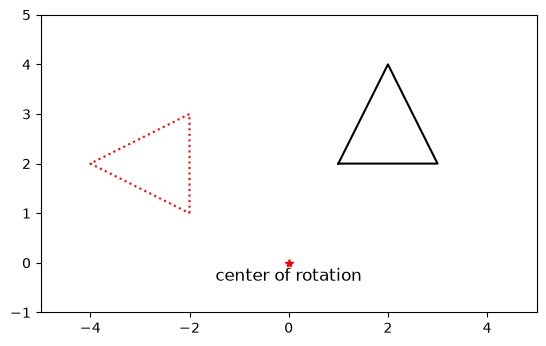

In [4]:
import matplotlib.pyplot as plt
x = np.array([ [1, 3, 2, 1], [2, 2, 4, 2] ])
fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.axis([-5,5,-1,5])
ax.plot(x[0], x[1], 'k-')
ax.plot(0, 0, '*r')
ax.text(0,-0.1,'center of rotation', fontsize=12, ha='center', va='top')
xs = R@x
ax.plot(xs[0], xs[1], 'r:')

## How to apply a rotation to more than one shape in 2D?
To apply a rotation to multiple shapes, we store the data for all shapes in a single matrix and perform the rotation using one matrix multiplication.
The data for different shapes must be separated by `numpy.nan` within the matrix.

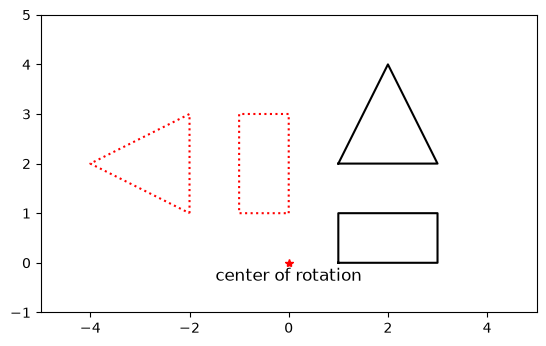

In [5]:
y = np.array([ [1, 3, 3, 1, 1], [0, 0, 1, 1, 0] ])
nan = np.array([[np.nan],[np.nan]])
xy = np.concatenate((x, nan, y), axis=1)
fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.axis([-5,5,-1,5])
ax.plot(xy[0], xy[1], 'k-')
ax.plot(0, 0, '*r')
ax.text(0,-0.1,'center of rotation', fontsize=12, ha='center', va='top')
xys = R@xy
ax.plot(xys[0], xys[1], 'r:')

## How to rotate about an arbitrary center point?
To rotate about the center point with the coordinates $(c_1 | c_2)$ we will proceed in three steps:
- Translate the shape so that $(c_1 | c_2)$ becomes the origin:
$$
\begin{bmatrix}
x_1' \\
x_2'
\end{bmatrix}
=
\begin{bmatrix}
x_1 \\
x_2
\end{bmatrix}
-
\begin{bmatrix}
c_1 \\
c_2
\end{bmatrix}
$$
- Apply the rotation around the origin:
$$
\begin{bmatrix}
x_1'' \\
x_2''
\end{bmatrix}
=
\underbrace{
\begin{bmatrix}
\cos{\alpha} & -\sin{\alpha} \\
\sin{\alpha} &  \cos{\alpha} \\
\end{bmatrix}
}_{\displaystyle \mathbf{R}}
\begin{bmatrix}
x_1' \\
x_2'
\end{bmatrix}
$$
- Translate back to the original position:
$$
\begin{bmatrix}
x_1''' \\
x_2'''
\end{bmatrix}
=
\begin{bmatrix}
x_1'' \\
x_2''
\end{bmatrix}
+
\begin{bmatrix}
c_1 \\
c_2
\end{bmatrix}
$$

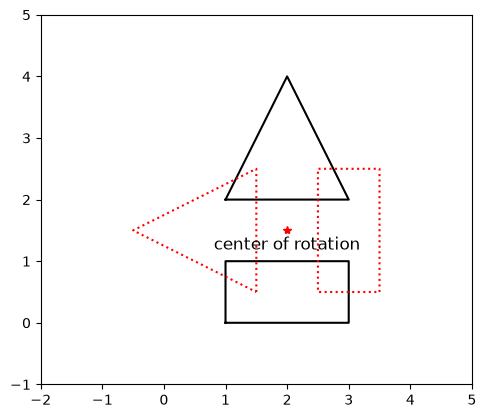

In [6]:
fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.axis([-2,5,-1,5])
ax.plot(xy[0], xy[1], 'k-')
c = np.array([[2.0],[1.5]])
ax.plot(c[0,0], c[1,0], '*r')
ax.text(c[0,0],c[1,0]-0.1,'center of rotation', fontsize=12, ha='center', va='top')
xys = xy - c
xyss = R@xys
xysss = xyss + c
ax.plot(xysss[0], xysss[1], 'r:')

# Conclusion
 - A rotation around the origin is performed by a multiplication with a rotation matrix.
 - If you want to rotate about an arbitrary center point you first have to apply a translation, then apply the rotation about the origin and then translate back.

# Did you get it?
<div class="alert alert-block alert-info">

<b>Task 1</b>
Draw the square defined by the points $(1|1)$, $(2|1)$, $(2|2)$ and $(1|2)$.
Then, rotate the square by an angle of $45°$ and draw the resulting rotated square.
</div>

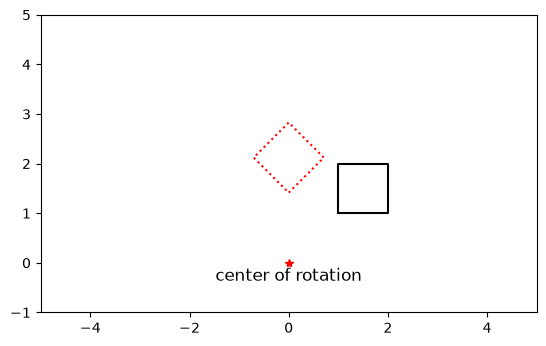

In [9]:
# Task 1

np.set_printoptions(precision=3, suppress=True)
alpha = np.pi/4
R = np.array([ [np.cos(alpha),-np.sin(alpha)], [np.sin(alpha), np.cos(alpha)] ])

y = np.array([ [1, 2, 2, 1, 1], [1, 1, 2, 2, 1] ])

fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.axis([-5,5,-1,5])
ax.plot(y[0], y[1], 'k-')
ax.plot(0, 0, '*r')
ax.text(0,-0.1,'center of rotation', fontsize=12, ha='center', va='top')
ys = R@y
ax.plot(ys[0], ys[1], 'r:')

## Literature
- https://youtu.be/???